# 01 - Exploratory Data Analysis

**Goal:** understand the two datasets *before* modelling, with a focus on the sensitive groups.

Questions this notebook answers:
1. How large is each dataset and how balanced is the target?
2. How many people are in each demographic group?
3. Do the groups have different **base rates** (share of positive outcomes)? This matters because a model
   that copies the data will reproduce those differences - a demographic-parity gap can come from the data itself.
4. Which features are strongly associated with the sensitive attribute (possible **proxies**)?

In [1]:
# --- Setup: works both in Google Colab and locally ---------------------------
# Colab: choose ONE way to get the project:
#   (a) USE_DRIVE = True  -> upload the fairness-xai folder to "My Drive"
#   (b) REPO_URL = "..."  -> clone it from GitHub
# Locally (Jupyter / VS Code) nothing needs changing.
import importlib.metadata
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False
DRIVE_PROJECT = "/content/drive/MyDrive/fairness-xai"
REPO_URL = ""  # e.g. "https://github.com/<your-user>/fairness-xai.git"

if IN_COLAB:
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_ROOT = Path(DRIVE_PROJECT)
    elif REPO_URL:
        PROJECT_ROOT = Path("/content/fairness-xai")
        if not PROJECT_ROOT.exists():
            subprocess.run(["git", "clone", REPO_URL, str(PROJECT_ROOT)], check=True)
    else:
        raise RuntimeError("Set USE_DRIVE = True or REPO_URL so Colab can find the project.")
    # Install the pinned versions once. If Colab then asks to "Restart session",
    # click it and run this cell again - the install is skipped the second time.
    try:
        already = importlib.metadata.version("shap") == "0.48.0"
    except importlib.metadata.PackageNotFoundError:
        already = False
    if not already:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(PROJECT_ROOT / "requirements.txt")], check=True)
else:
    # Locally the notebook runs from notebooks/, so the project root is its parent.
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: C:\Users\tarun\Desktop\Mini Project\fairness-xai


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

from src import config
from src.data import COMPAS_LEAKAGE_COLUMNS, load_adult, load_compas

config.setup_logging()
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Load both datasets
The loaders apply all cleaning rules (see `src/data.py`).

In [3]:
datasets = {"adult": load_adult(), "compas": load_compas()}
for name, d in datasets.items():
    print(f"{config.DATASET_DISPLAY_NAMES[name]}: {d.X.shape[0]:,} rows, {d.X.shape[1]} features")
    print("   numeric:    ", d.metadata.numeric)
    print("   categorical:", d.metadata.categorical)
    print("   sensitive:  ", d.metadata.sensitive_attributes, "| privileged:", d.metadata.privileged)

21:25:31 | INFO    | src.data | Loaded Adult from OpenML via fairlearn (48842 rows).


21:25:31 | INFO    | src.data | Adult ready: 45222 rows, 12 features, positive rate 0.248.


21:25:31 | INFO    | src.data | COMPAS ready: 5278 rows, 8 features, positive rate 0.470.


Adult Income: 45,222 rows, 12 features
   numeric:     ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
   categorical: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
   sensitive:   ['sex', 'race'] | privileged: {'sex': 'Male', 'race': 'White'}
COMPAS: 5,278 rows, 8 features
   numeric:     ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count']
   categorical: ['sex', 'race', 'c_charge_degree']
   sensitive:   ['race', 'sex'] | privileged: {'race': 'Caucasian', 'sex': 'Female'}


In [4]:
display(datasets["adult"].X.head())
display(datasets["compas"].X.head())

,age,education-num,capital-gain,capital-loss,hours-per-week,workclass,marital-status,occupation,relationship,race,sex,native-country
0,25,7,0,0,40,Private,Never-married,Machine-op-inspct,Own-child,Non-White,Male,United-States
1,38,9,0,0,50,Private,Married-civ-spouse,Farming-fishing,Husband,White,Male,United-States
2,28,12,0,0,40,Local-gov,Married-civ-spouse,Protective-serv,Husband,White,Male,United-States
3,44,10,7688,0,40,Private,Married-civ-spouse,Machine-op-inspct,Husband,Non-White,Male,United-States
4,34,6,0,0,30,Private,Never-married,Other-service,Not-in-family,White,Male,United-States


,age,priors_count,juv_fel_count,juv_misd_count,juv_other_count,sex,race,c_charge_degree
0,34,0,0,0,0,Male,African-American,F
1,24,4,0,0,1,Male,African-American,F
2,41,14,0,0,0,Male,Caucasian,F
3,39,0,0,0,0,Female,Caucasian,M
4,27,0,0,0,0,Male,Caucasian,F


## 2. Leakage check (COMPAS)
`decile_score`, `score_text` and `v_decile_score` are the COMPAS tool's own risk scores. Using them as features
would be **target leakage** (and would copy the tool's bias), so they must not be in `X`.

In [5]:
leaked = [c for c in COMPAS_LEAKAGE_COLUMNS if c in datasets["compas"].X.columns]
print("Leakage columns present in COMPAS features:", leaked or "none")

Leakage columns present in COMPAS features: none


## 3. Target balance
Accuracy alone is misleading when classes are imbalanced, so we also report F1 and ROC-AUC later.

In [6]:
balance = pd.DataFrame({
    config.DATASET_DISPLAY_NAMES[n]: d.y.value_counts(normalize=True).sort_index()
    for n, d in datasets.items()
}).rename(index={0: "negative (0)", 1: "positive (1)"})
display(balance.round(3))

,Adult Income,COMPAS
negative (0),0.752,0.53
positive (1),0.248,0.47


## 4. Group sizes and base rates
The **base rate** of a group is the share of its members with `y = 1` in the data
(Adult: earns >50K; COMPAS: re-offended within two years).

In [7]:
rows = []
for name, d in datasets.items():
    for attr in d.metadata.sensitive_attributes:
        for group, idx in d.sensitive.groupby(attr).groups.items():
            rows.append({
                "dataset": name, "attribute": attr, "group": group,
                "privileged": group == d.metadata.privileged[attr],
                "count": len(idx), "share_of_rows": len(idx) / len(d.X),
                "base_rate": d.y.loc[idx].mean(),
            })
base_rates = pd.DataFrame(rows)
display(base_rates.round(3))

,dataset,attribute,group,privileged,count,share_of_rows,base_rate
0,adult,sex,Female,False,14695,0.325,0.114
1,adult,sex,Male,True,30527,0.675,0.312
2,adult,race,Non-White,False,6319,0.140,0.158
3,adult,race,White,True,38903,0.860,0.262
4,compas,race,African-American,False,3175,0.602,0.523
5,compas,race,Caucasian,True,2103,0.398,0.391
6,compas,sex,Female,True,1031,0.195,0.362
7,compas,sex,Male,False,4247,0.805,0.497


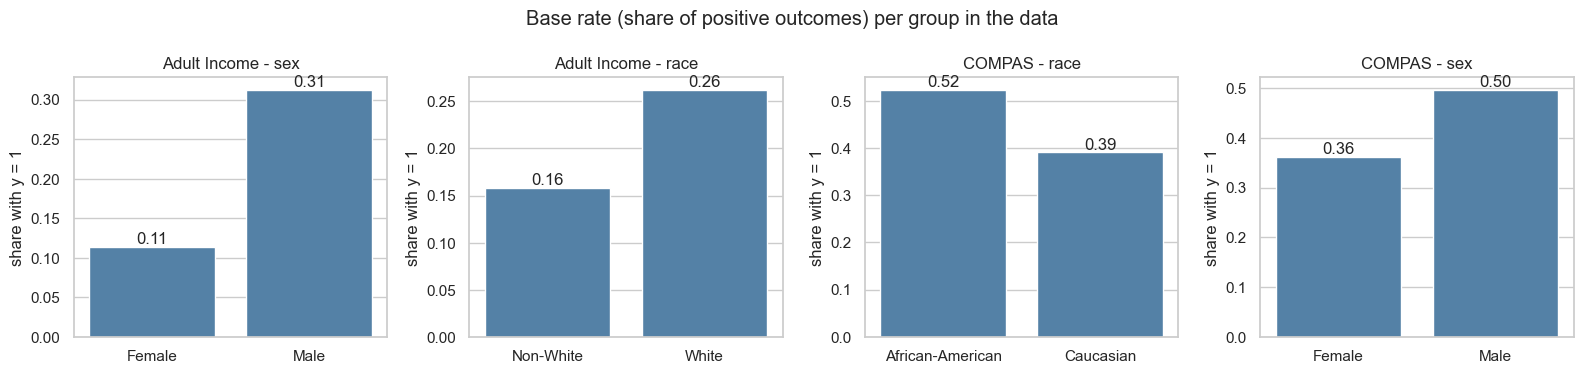

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, ((name, attr), part) in zip(axes, base_rates.groupby(["dataset", "attribute"], sort=False)):
    sns.barplot(data=part, x="group", y="base_rate", ax=ax, color="steelblue")
    ax.set_title(f"{config.DATASET_DISPLAY_NAMES[name]} - {attr}")
    ax.set_ylabel("share with y = 1")
    ax.set_xlabel("")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f")
fig.suptitle("Base rate (share of positive outcomes) per group in the data")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "eda_base_rates.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# The same information as plain sentences, computed from the table above.
for (name, attr), part in base_rates.groupby(["dataset", "attribute"], sort=False):
    a, b = part.iloc[0], part.iloc[1]
    print(f"{config.DATASET_DISPLAY_NAMES[name]}, {attr}: base rate {a.group} = {a.base_rate:.1%}, "
          f"{b.group} = {b.base_rate:.1%} (gap {abs(a.base_rate - b.base_rate):.1%}).")

Adult Income, sex: base rate Female = 11.4%, Male = 31.2% (gap 19.9%).
Adult Income, race: base rate Non-White = 15.8%, White = 26.2% (gap 10.4%).
COMPAS, race: base rate African-American = 52.3%, Caucasian = 39.1% (gap 13.2%).
COMPAS, sex: base rate Female = 36.2%, Male = 49.7% (gap 13.5%).


**Why this matters for fairness:** if base rates differ, even a perfectly accurate model will predict the positive
class more often for one group, so it will have a demographic-parity gap. That is why we also use
**equal opportunity** (equal true positive rates), which compares groups only among people who really are positive.

## 5. Numeric features by group

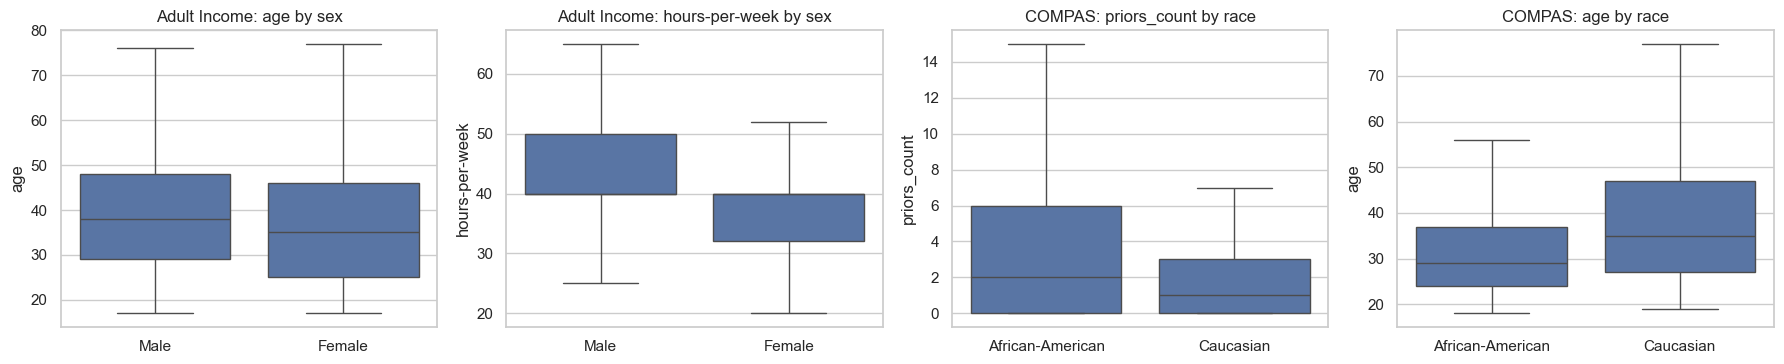

In [10]:
plots = [("adult", "sex", "age"), ("adult", "sex", "hours-per-week"),
         ("compas", "race", "priors_count"), ("compas", "race", "age")]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (name, attr, feature) in zip(axes, plots):
    d = datasets[name]
    frame = d.X[[feature]].assign(group=d.sensitive[attr])
    sns.boxplot(data=frame, x="group", y=feature, ax=ax, showfliers=False)
    ax.set_title(f"{config.DATASET_DISPLAY_NAMES[name]}: {feature} by {attr}")
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "eda_numeric_by_group.png", dpi=120, bbox_inches="tight")
plt.show()

## 6. Possible proxies
A **proxy** is a feature that is strongly associated with a sensitive attribute. Even if we remove `sex` from the
inputs, the model can partly recover it from a proxy. In Adult, `relationship` contains the values
*Husband* and *Wife*, which almost reveal sex. Phase 4 selects proxies automatically by mutual information;
here we just look at the cross-tabulations.

In [11]:
adult = datasets["adult"]
display(pd.crosstab(adult.X["relationship"], adult.sensitive["sex"], normalize="index").round(3))

sex,Female,Male
relationship,,
Husband,0.000,1.000
Not-in-family,0.462,0.538
Other-relative,0.452,0.548
Own-child,0.442,0.558
Unmarried,0.763,0.237
Wife,1.000,0.000


In [12]:
compas = datasets["compas"]
display(compas.X.groupby(compas.sensitive["race"])[["priors_count", "juv_fel_count", "juv_misd_count", "age"]]
        .mean().round(2))

,priors_count,juv_fel_count,juv_misd_count,age
race,,,,
African-American,4.24,0.09,0.14,32.43
Caucasian,2.29,0.03,0.04,37.49


## Summary
* Both datasets load cleanly, with no missing values and no COMPAS leakage columns.
* The groups differ in size (e.g. far fewer Non-White than White rows in Adult) and in base rate, as printed above.
* Some features are strongly associated with the sensitive attributes, so removing the sensitive column alone may not
  remove its influence. Later phases measure this directly.

Next: `02_preprocess_train.ipynb` - split, preprocess, train and evaluate the models.